In [102]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [94]:
df = pd.read_csv('data/QuizData.csv')
df.head(2)

,total,reception
0,118,62
1,253,148


In [107]:
data = df.iloc[:,:-1].values
label = df.iloc[:,1:].values

data[:2]
label[:2]

array([[ 62],
       [148]])

In [96]:
train_data,test_data,trian_label,test_label = train_test_split(data,label)


In [100]:
# 데이터 학습 
lr = LinearRegression()
lr.fit(train_data,trian_label)

# 데이터 예측 
predict = lr.predict(test_data)
print('예측 식사 인원 :', predict)

# 정확도 
score = lr.score(train_data,trian_label)
score2 = lr.score(test_data,test_label)
print('train 정확도 :', score)
print('test 정확도 :', score2)


예측 식사 인원 : [[ 87.15297378]
 [ 75.18968749]
 [ 94.97512251]
 [156.17193316]
 [117.98144231]]
train 정확도 : 0.8502577616377248
test 정확도 : 0.801220622203144


In [98]:
in_data = input(' 참석인원을 입력하세요. 예), ')
in_data = float(in_data)
result = lr.predict([[in_data]])
print('예측 식사 인원 : ', result)

예측 식사 인원 :  [[173.6567362]]


In [104]:
lr.coef_

array([[0.4601264]])

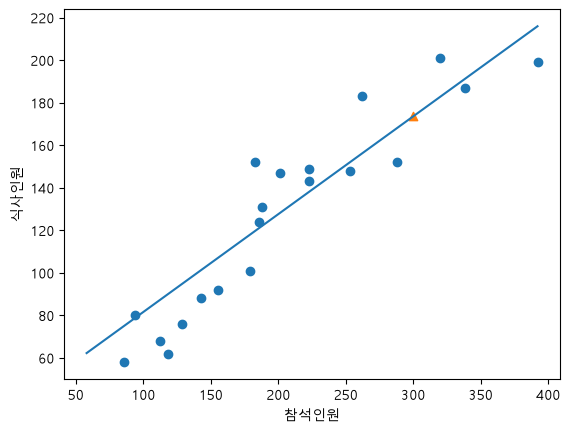

In [113]:
# 산점도 그래프
plt.scatter(data,label)
plt.scatter(in_data,result, marker='^')
plt.plot([58,392],[58*lr.coef_[0]+lr.intercept_,392*lr.coef_[0]+lr.intercept_])  # 선그래프 
plt.xlabel("참석인원")
plt.ylabel("식사인원")
plt.show()